## The Data

We will be working with a famous titanic data set for these exercises. Later on in the Machine Learning section of the course, we will revisit this data, and use it to predict survival rates of passengers. For now, we'll just focus on the visualization of the data with seaborn:

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# %matplotlib inline

In [7]:
sns.set_style('whitegrid')

In [2]:
titanic = sns.load_dataset('titanic')

## Show head of data

In [3]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


## check null value

In [5]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

# Exercises

## 1. What is the distribution of passengers’ ages?

Text(0.5, 0, 'Age')

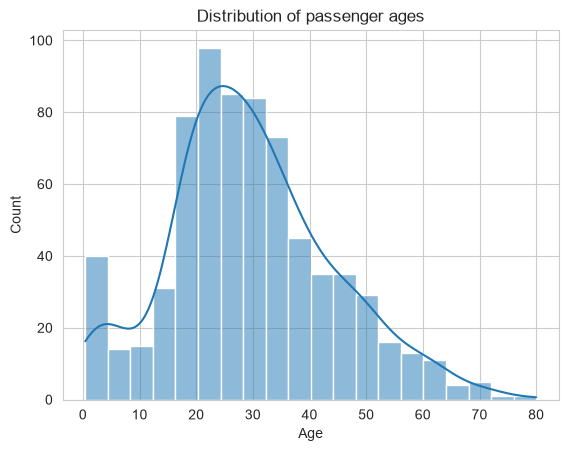

In [10]:
# plot here

sns.histplot(titanic['age'].dropna(), kde=True)
plt.title('Distribution of passenger ages')
plt.xlabel('Age')



## 2. What is the distribution of passengers’ ages and fare ?
each figure in subplot

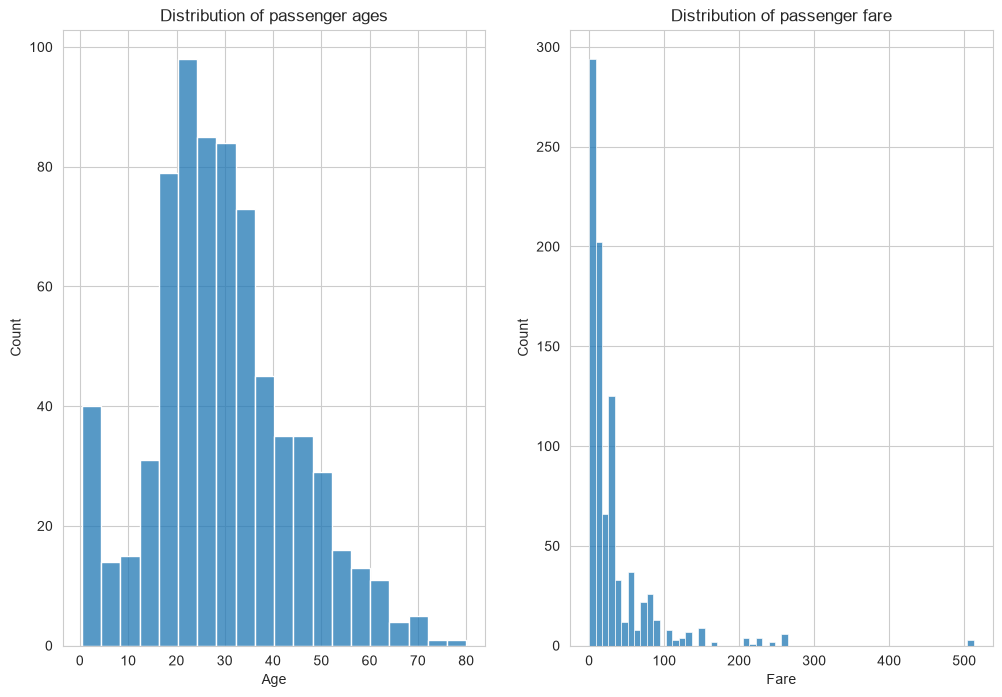

In [27]:
plt.figure(figsize=(12,8))
plt.subplot(1,2,1)
sns.histplot(titanic['age'].dropna())
plt.title('Distribution of passenger ages')
plt.xlabel('Age')

plt.subplot(1,2,2)
sns.histplot(titanic['fare'])
plt.title('Distribution of passenger fare')
plt.xlabel('Fare')

plt.show()

## 3. What is the relationship between age and fare?

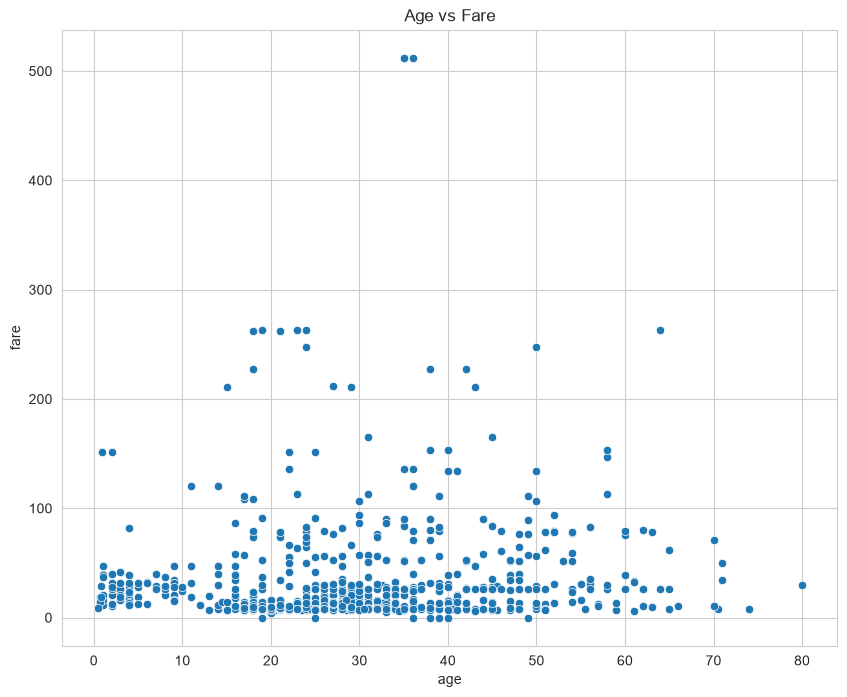

In [32]:
# plot here

plt.figure(figsize=(10,8))
sns.scatterplot(x='age', y='fare', data=titanic)
plt.title('Age vs Fare')
plt.show()

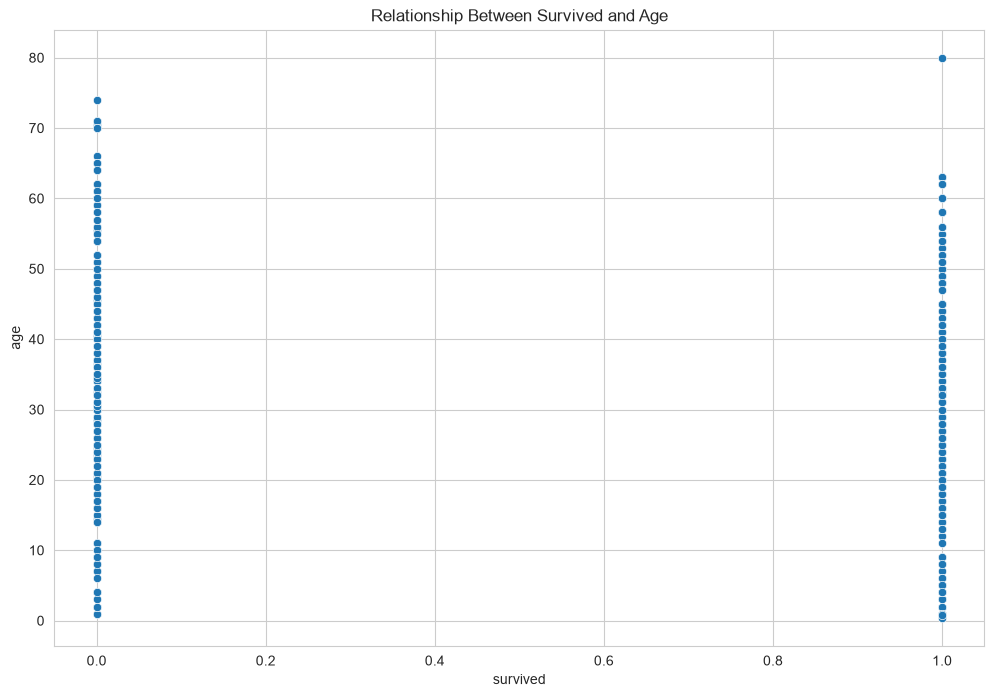

In [33]:
plt.figure(figsize=(12,8))
sns.scatterplot(x='survived', y='age', data=titanic)
plt.title('Relationship Between Survived and Age')
plt.show()

## 4. What is the relationship between survived and age?

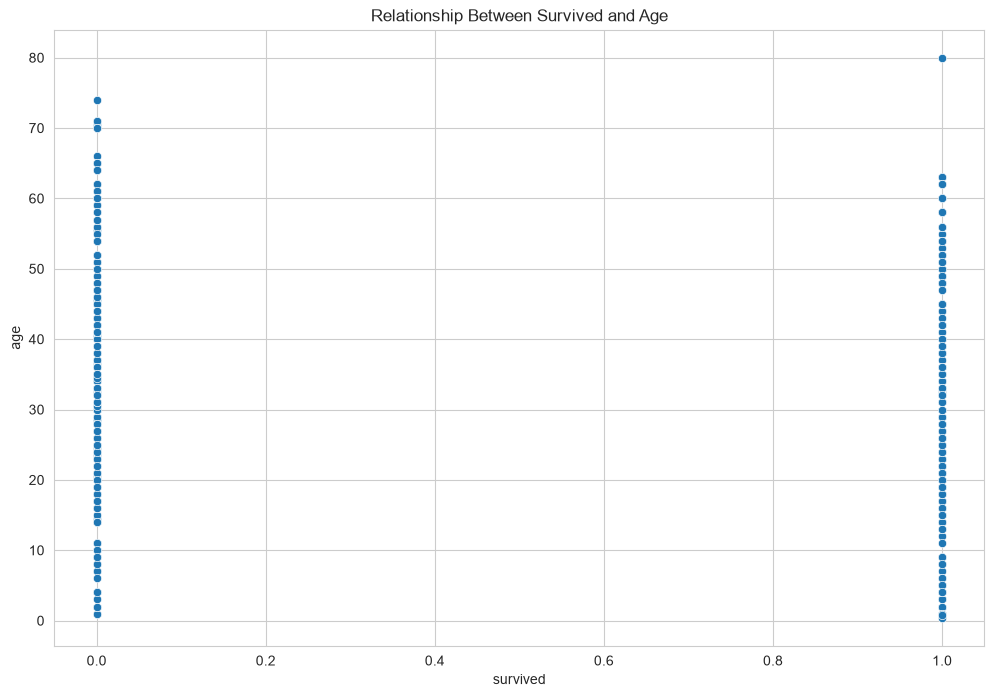

In [34]:
# plot here

plt.figure(figsize=(12,8))
sns.scatterplot(x='survived', y='age', data=titanic)
plt.title('Relationship Between Survived and Age')
plt.show()

## 5. How does the survival rate vary by gender?

In [48]:
# get mean of survived when column of sex == male

male_surv = titanic[ titanic['sex'] == 'male']['survived'].mean()
print(male_surv)

0.18890814558058924


In [49]:
# get mean of survived when column of sex == female

female_surv = titanic[ titanic['sex'] == 'female']['survived'].mean()
print(female_surv)

0.7420382165605095


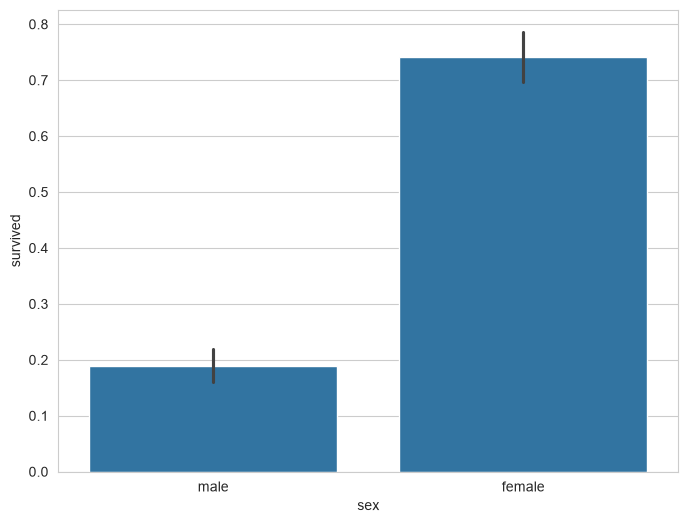

In [52]:
# plot here

plt.figure(figsize=(8,6))
sns.barplot(x='sex', y='survived', data=titanic)
plt.show()


## 6. How does the survival rate vary by passenger class?

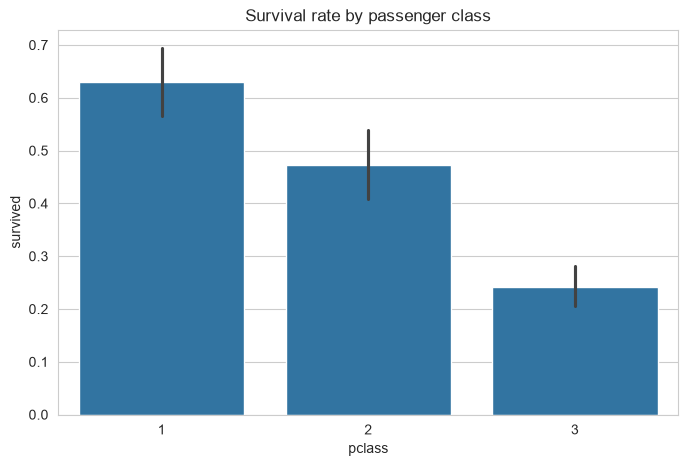

In [60]:
# plot here

plt.figure(figsize=(8,5))
sns.barplot(x='pclass', y='survived', data=titanic)
plt.title('Survival rate by passenger class')
plt.show()

## 7. Survival Rate by Age Group

we are dividing the passengers' ages into 5 distinct age groups:
- Ages from 0 to 12 fall into the first bin (typically classified as "Child").
- Ages from 12 to 18 fall into the second bin (classified as "Teen").
- Ages from 18 to 35 fall into the third bin (classified as "Adult").
- Ages from 35 to 60 fall into the fourth bin (classified as "Middle-Aged").
- Ages from 60 to 80 fall into the fifth bin (classified as "Senior").

using pd.cut(data,bins,labels)

In [62]:
bins = [0,12,18,35,60,80]
label = ['Child', 'Teen', 'Adult', 'Middle-Age', 'Senior']

In [ ]:
# Create age groups

titanic['Age Group'] = pd.cut(titanic['age'], bins=bins, labels=label)
titanic[['age', 'Age Group']].head()

0          Adult
1    Middle-Aged
2          Adult
3          Adult
4          Adult
Name: age_group, dtype: category
Categories (5, object): ['Child' < 'Teen' < 'Adult' < 'Middle-Aged' < 'Senior']

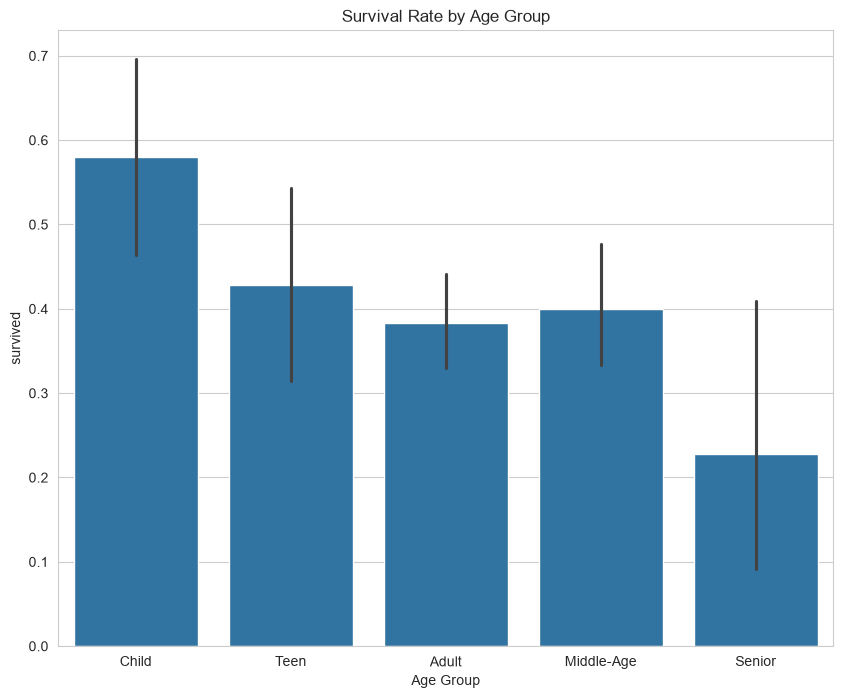

In [72]:
# plot here

plt.figure(figsize=(10,8))
sns.barplot(x='Age Group', y='survived', data=titanic)
plt.title('Survival Rate by Age Group')
plt.show()

## 8. Survival Rate by Embarkation Point for each sex 

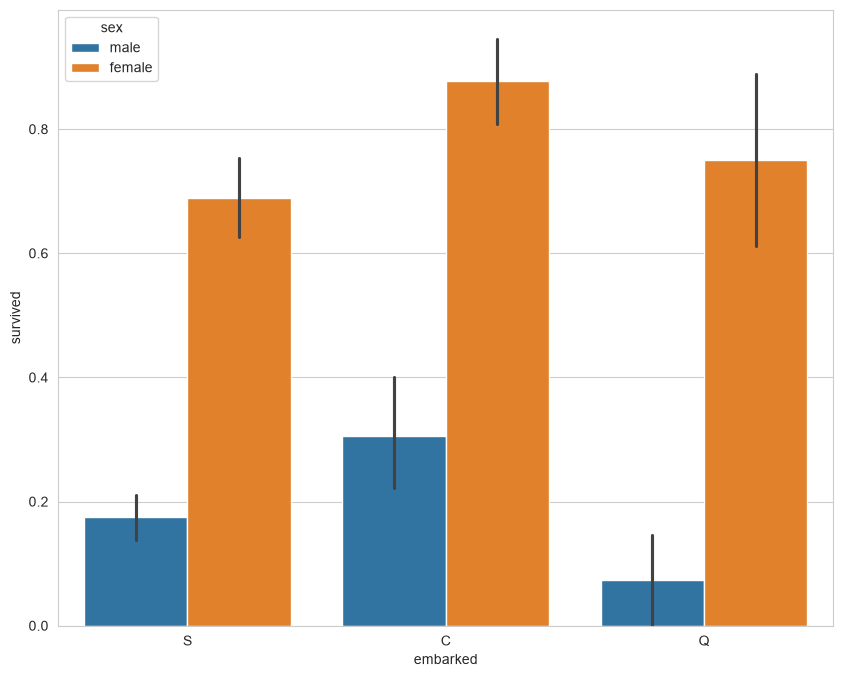

In [74]:
# plot here

plt.figure(figsize=(10,8))
sns.barplot(x='embarked', y='survived',hue='sex', data=titanic)
plt.show()



## 9. Counting of Passengers by pclass for each sex

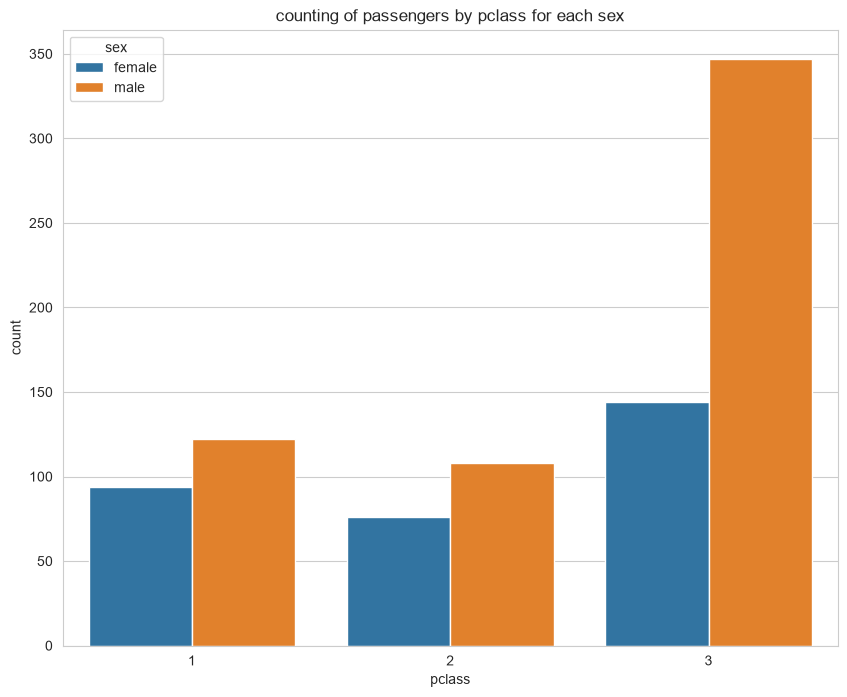

In [78]:
# plot here
plt.figure(figsize=(10,8))
sns.countplot(x='pclass', hue='sex', data=titanic)
plt.title('counting of passengers by pclass for each sex')
plt.show()

In [57]:
titanic.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone', 'age_group'],
      dtype='object')

## 10. Counting of Passengers by class for each who

Text(0.5, 1.0, 'Distribution of passengers by class and who')

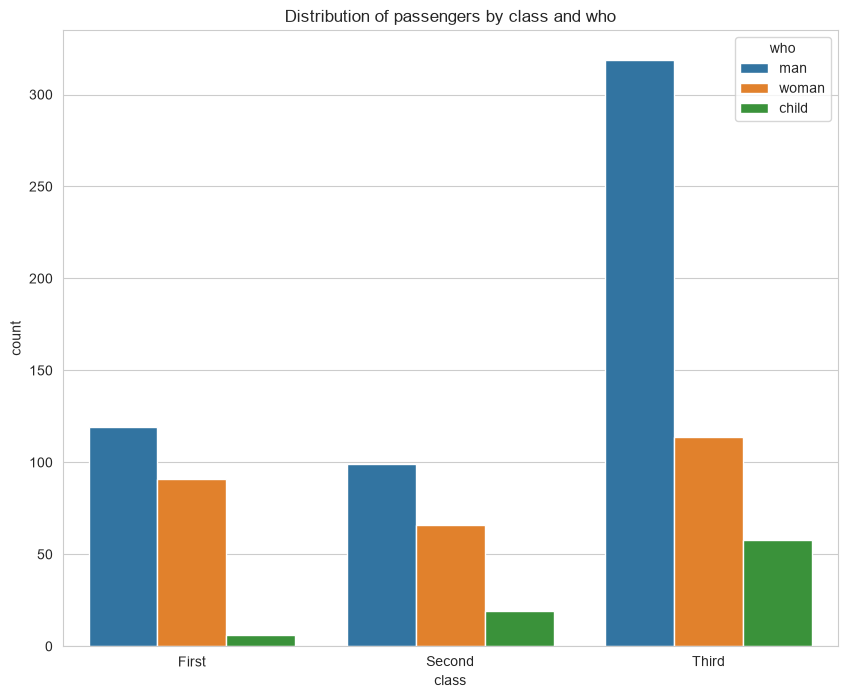

In [80]:
# plot here
plt.figure(figsize=(10,8))
sns.countplot(x='class', hue='who', data=titanic)
plt.title('Distribution of passengers by class and who')

## 11. How many males and females were on board across different classes?

<Axes: xlabel='pclass', ylabel='count'>

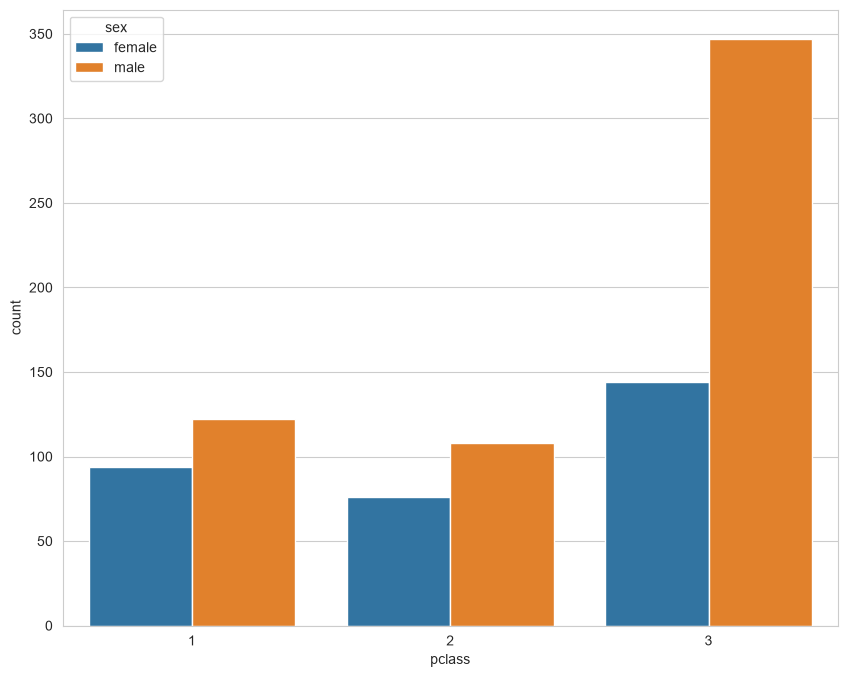

In [82]:
# plot here
plt.figure(figsize=(10,8))
sns.countplot(x='pclass', hue='sex', data=titanic)

## 12. How does the survival rate vary by embarkation port?

<Axes: xlabel='embark_town', ylabel='survived'>

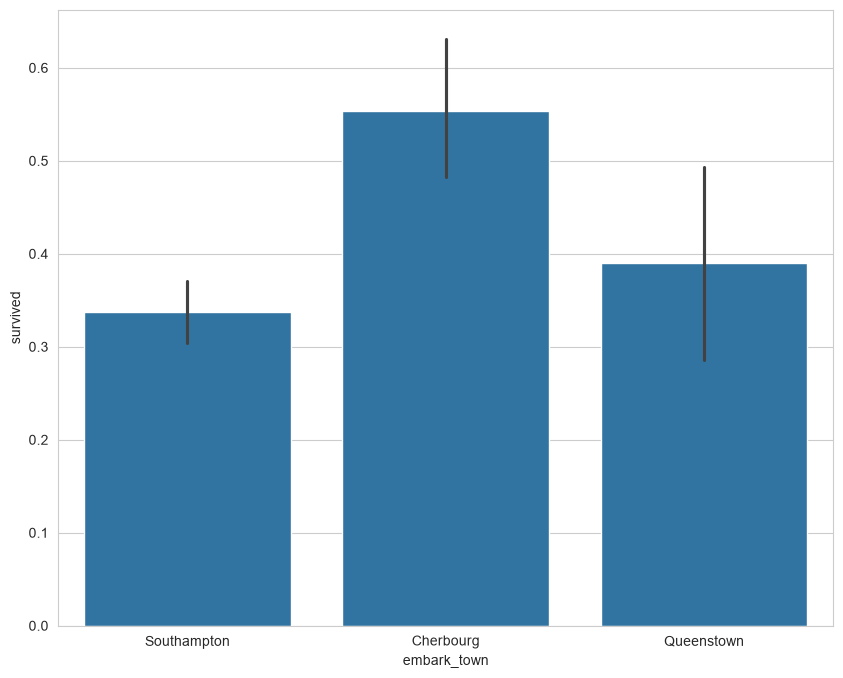

In [83]:
# plot here

plt.figure(figsize=(10,8))
sns.barplot(x='embark_town', y='survived', data=titanic)

## 13. Correlation Heatmap

In [85]:
# get column with number value
num_col = titanic.select_dtypes(include='number')
num_col.columns

Index(['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare'], dtype='str')

In [86]:
num_col.corr()

,survived,pclass,age,sibsp,parch,fare
survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
sibsp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


<Axes: >

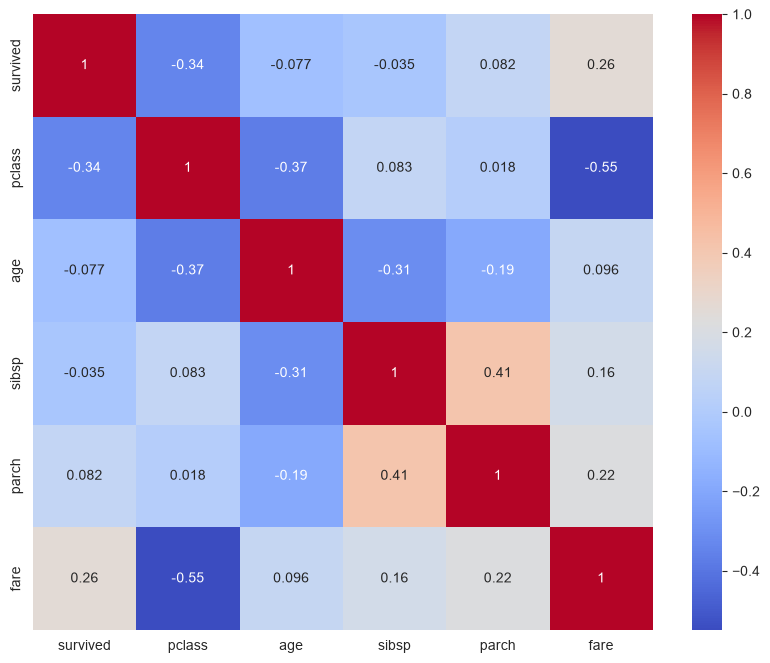

In [90]:
# plot here

plt.figure(figsize=(10,8))
sns.heatmap(num_col.corr(), annot=True, cmap='coolwarm')

## 14. What is the distribution of passengers' fare based on their gender and survival status?
boxplot

<Axes: xlabel='sex', ylabel='fare'>

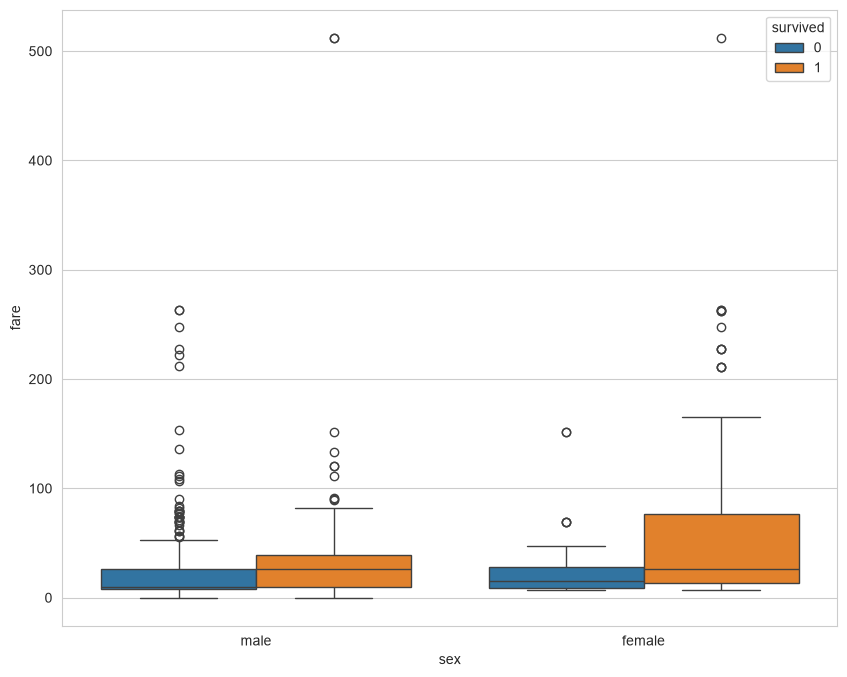

In [93]:
# plot here
plt.figure(figsize=(10,8))
sns.boxplot(x='sex', y='fare', hue='survived', data=titanic)

## 15. What is the relationship between class, gender, and survival rate?
pointplot()

<Axes: xlabel='pclass', ylabel='survived'>

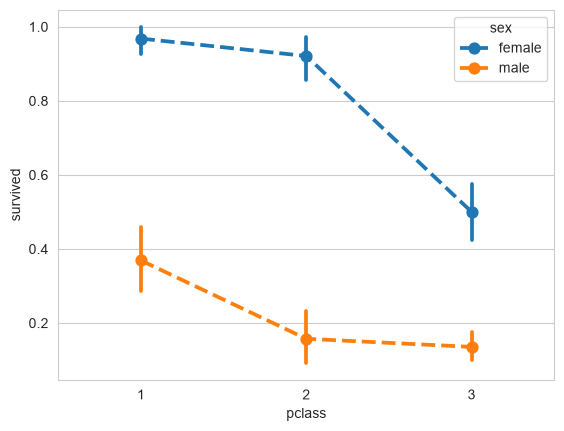

In [97]:
# plot here
sns.pointplot(x='pclass', y='survived', hue='sex', data=titanic, linestyles='dashed')

# Great Job!

